# Setup & Imports


In [63]:
import torch
import torchhd as hd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef

# CORE CONFIGURATION
D = 5000
NUM_LEVELS = 100
EPOCHS = 50
RANDOM_SEED = 42

# NEW DIRECTORY CONFIGURATION
RESULTS_DIR = "Final_Final_SurpriseResults_5000"
if not os.path.exists(RESULTS_DIR): 
    os.makedirs(RESULTS_DIR)

RESULTS_CV_FILE = os.path.join(RESULTS_DIR, "hdc_official_cv_results.csv")
RESULTS_TEST_FILE = os.path.join(RESULTS_DIR, "hdc_official_test_results.csv")

# SET SEEDS FOR REPRODUCIBILITY
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} | Dimensionality (D): {D}")
print(f"Results will be saved to: {RESULTS_DIR}/")

Using device: cpu | Dimensionality (D): 5000
Results will be saved to: Final_Final_SurpriseResults_5000/


# Data loading & preparation

In [ ]:
# --- CONFIG PATHS ---
BASE_DIR    = ...
GRAPH_DIR   = ...

# 1. Identify Primary Tumors and Load Subtypes
master_sheet = pd.read_csv("Ovary/sample_sheet.tsv", sep="\t")
master_sheet.columns = [c.strip('"').strip() for c in master_sheet.columns]
primary_tumor_ids = master_sheet[master_sheet["Sample.Type"] == "Primary Tumor"]["Sample.ID"].unique()

pheno = pd.read_csv("Ovary/sample_sheet_subtypes.tsv", sep="\t", header=None, names=["Sample.ID", "Subtype"])
pheno = pheno[pheno["Sample.ID"].isin(primary_tumor_ids)].copy()

# 2. Map Subtypes to labels
subtype_mapping = {"HGSOC_Proliferative": 0, "HGSOC_Mesenchymal": 1, "HGSOC_Immunoreactive": 2, "HGSOC_Differentiated": 3}
pheno["label"] = pheno["Subtype"].map(subtype_mapping)
pheno = pheno.dropna(subset=["label"])

# 3. Build File Index
graph_file_map = {f.replace("meanSum_", "").replace(".graphml", ""): f for f in os.listdir(GRAPH_DIR) if f.endswith(".graphml")}
pheno["short_id"] = pheno["Sample.ID"].str.split("-").str[:4].str.join("-")
pheno = pheno[pheno["short_id"].isin(graph_file_map.keys())]

# 4. Load the Graphs into Memory
import networkx as nx
new_graphs = {}
print(f"Loading {len(pheno)} validated Primary Tumor graphs...")

for i, (_, row) in enumerate(pheno.iterrows(), 1):
    sid = row["short_id"]
    filename = graph_file_map[sid]
    G = nx.read_graphml(os.path.join(GRAPH_DIR, filename))
    new_graphs[sid] = {"graph": G, "project": row["Subtype"], "label": int(row["label"])}

# 5. Stratified Split
graph_ids = list(new_graphs.keys())
y_all = np.array([new_graphs[gid]["label"] for gid in graph_ids])

ids_train, ids_test, y_train, y_test = train_test_split(
    graph_ids, y_all, train_size=0.8, stratify=y_all, random_state=RANDOM_SEED
)

print(f"Loading Complete. Train: {len(ids_train)} | Test: {len(ids_test)}")

Loading 290 validated Primary Tumor graphs...
Loading Complete. Train: 232 | Test: 58


# HDC Core Functions

In [65]:
def run_variance_analysis(ids_train, new_graphs, top_percent):
    print(f"Analyzing variance for top {top_percent}% edges...")
    train_edges = set()
    for gid in ids_train: train_edges.update(new_graphs[gid]["graph"].edges)
    
    edge_stats = []
    for edge in sorted(train_edges):
        u, v = edge
        weights = [float(new_graphs[gid]["graph"][u][v].get("weight", 0.0)) 
                   for gid in ids_train if new_graphs[gid]["graph"].has_edge(u, v)]
        if len(weights) >= 2:
            edge_stats.append([f"{u}-{v}", np.var(weights, ddof=1), np.mean(weights), np.std(weights, ddof=1) or 1.0])
    
    df_stats = pd.DataFrame(edge_stats, columns=["edge", "variance", "mu", "sigma"])
    k_edges = int(len(df_stats) * top_percent / 100)
    top_df = df_stats.nlargest(k_edges, "variance")
    return top_df["edge"].tolist(), {row.edge: (row.mu, row.sigma) for _, row in top_df.iterrows()}

def encode_data(ids_list, top_edge_list, edge_mu_sigma, metabolite_memory, level_shvs):
    encoded = []
    for gid in ids_list:
        G = new_graphs[gid]["graph"]
        h = torch.zeros(D)
        for edge_str in top_edge_list:
            u, v = edge_str.split("-")
            if G.has_edge(u, v):
                mu, sigma = edge_mu_sigma[edge_str]
                z_w = (float(G[u][v].get("weight", 0.0)) - mu) / sigma
                scaled_w = 1.0 / (1.0 + np.exp(-z_w))
                level_idx = min(int(scaled_w * NUM_LEVELS), NUM_LEVELS - 1)
                edge_id = hd.bind(hd.permute(metabolite_memory[u]), metabolite_memory[v])
                h = hd.bundle(h, hd.bind(edge_id, level_shvs[level_idx]))
        encoded.append(hd.normalize(h))
    return torch.stack(encoded)

def train_retrainer(train_hvs, train_labels, method='surprise', lr=0.01, margin=0.01, epochs=50):
    if not isinstance(train_labels, torch.Tensor):
        train_labels = torch.tensor(train_labels)
        
    train_hvs = train_hvs.to(torch.float64)
    classes = torch.unique(train_labels)

    prototypes = {c.item(): hd.multiset(train_hvs[train_labels == c]).to(torch.float64) for c in classes}
    initial_protos = {c: hd.normalize(p.clone()) for c, p in prototypes.items()}
    
    history = []
    torch.manual_seed(RANDOM_SEED) # Lock inner stochastic variance
    
    for epoch in range(epochs):
        updates = 0
        curr_lr = max(lr * (0.95 ** epoch), 0.001) 
        perm = torch.randperm(train_hvs.size(0))
        
        for idx in perm:
            sample_hv = train_hvs[idx]; actual = train_labels[idx].item()
            with torch.no_grad():
                sims = {c: hd.cosine_similarity(sample_hv, hd.normalize(p)).item() for c, p in prototypes.items()}
            
            sorted_sims = sorted(sims.items(), key=lambda x: x[1], reverse=True)
            top_class = sorted_sims[0][0]
            is_wrong = (top_class != actual)
            is_low_conf = (sims[actual] - sorted_sims[1][1] if len(sorted_sims)>1 else 0.0) < margin

            if is_wrong or is_low_conf:
                updates += 1
                weight = curr_lr * (1.0 - sims[actual]) if method == 'surprise' else curr_lr

                prototypes[actual] += (sample_hv * weight)
                if is_wrong and method != 'pull_only':
                    prototypes[top_class] -= (sample_hv * weight)
                        
        history.append(updates)
        if updates == 0: break
        
    final_protos = {c: hd.normalize(p) for c, p in prototypes.items()}
    shifts = {c.item(): 1.0 - hd.cosine_similarity(initial_protos[c.item()], final_protos[c.item()]).item() for c in classes}
    avg_shift = sum(shifts.values()) / len(shifts)
    
    # Return initial_protos as well for t-SNE saving
    return final_protos, initial_protos, avg_shift, history

def evaluate(hvs, labels, protos):
    preds = []
    for hv in hvs:
        sims = {c: hd.cosine_similarity(hv, p).item() for c, p in protos.items()}
        preds.append(max(sims, key=sims.get))
    
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average='macro')
    
    # 1. Added labels, preds, macro average, and zero_division fallback
    prec = precision_score(labels, preds, average='macro', zero_division=0)
    
    # 2. Added Recall
    rec = recall_score(labels, preds, average='macro', zero_division=0)
    
    # 3. Added MCC
    mcc = matthews_corrcoef(labels, preds)
    
    # 4. Return all 5 metrics
    return acc, f1, prec, rec, mcc

# 10-fold CV Grid Search & Baseline Calculation

In [66]:
top_k_vals = [5, 90]
margins = [0.0, 0.005, 0.1]
lrs = [0.05, 0.1, 0.2, 0.5, 1]
method = 'surprise'

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
cv_results = []
baseline_cv_scores = {}

for k in top_k_vals:
    print(f"\n{'='*60}\n>>> RUNNING 10-FOLD CV: {k}% VARIANCE DENSITY\n{'='*60}")
    
    # 1. Global Encoding for this Density
    t_edges, e_stats = run_variance_analysis(ids_train, new_graphs, k)
    level_shvs = hd.level(NUM_LEVELS, D)
    met_mem = {}
    for gid in ids_train + ids_test:
        for node in new_graphs[gid]["graph"].nodes:
            if node not in met_mem: met_mem[node] = hd.random(1, D).squeeze(0)
            
    X_train_k = encode_data(ids_train, t_edges, e_stats, met_mem, level_shvs)
    y_train_tensor = torch.tensor(y_train)
    
    # 2. Establish 10-Fold Baseline (Single-Pass)
    # ADDED: List for MCC
    sp_fold_accs, sp_fold_f1s, sp_fold_precs, sp_fold_recs, sp_fold_mccs = [], [], [], [], []
    for train_idx, val_idx in skf.split(X_train_k, y_train):
        X_tr, y_tr = X_train_k[train_idx], y_train_tensor[train_idx]
        X_val, y_val = X_train_k[val_idx], y_train_tensor[val_idx]
        
        sp_protos = {c.item(): hd.normalize(hd.multiset(X_tr[y_tr == c])) for c in torch.unique(y_tr)}
        
        # ADDED: Catch mcc
        acc, f1, prec, rec, mcc = evaluate(X_val, y_val, sp_protos)
        sp_fold_accs.append(acc)
        sp_fold_f1s.append(f1)
        sp_fold_precs.append(prec)
        sp_fold_recs.append(rec)
        sp_fold_mccs.append(mcc)
        
    baseline_cv_scores[k] = {
        'Acc': np.mean(sp_fold_accs), 
        'SD_Acc': np.std(sp_fold_accs),
        'F1': np.mean(sp_fold_f1s),
        'SD_F1': np.std(sp_fold_f1s),
        'Prec': np.mean(sp_fold_precs), 
        'Rec': np.mean(sp_fold_recs),    
        'MCC': np.mean(sp_fold_mccs) # Tracked!
    }
    print(f"--- 10-Fold Baseline -> Acc: {baseline_cv_scores[k]['Acc']:.4f} (±{baseline_cv_scores[k]['SD_Acc']:.4f}) | F1: {baseline_cv_scores[k]['F1']:.4f} (±{baseline_cv_scores[k]['SD_F1']:.4f}) | Prec: {baseline_cv_scores[k]['Prec']:.4f} | Rec: {baseline_cv_scores[k]['Rec']:.4f} | MCC: {baseline_cv_scores[k]['MCC']:.4f} ---")    
    
    # 3. Grid Search over LR and Margin
    for m in margins:
        for lr in lrs:
            # ADDED: List for MCC
            fold_accs, fold_f1s, fold_precs, fold_recs, fold_mccs, fold_shifts = [], [], [], [], [], []
            print(f"Evaluating {method} | LR: {lr} | Margin: {m}...", end="")
            
            for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_k, y_train)):
                X_tr, y_tr = X_train_k[train_idx], y_train_tensor[train_idx]
                X_val, y_val = X_train_k[val_idx], y_train_tensor[val_idx]
                
                # Train Retrainer on 9/10 of the data
                final_p, init_p, shift, hist = train_retrainer(X_tr, y_tr, method, lr, m, EPOCHS)
                
                # Evaluate on 1/10 holdout
                # ADDED: Catch mcc
                acc, f1, prec, rec, mcc = evaluate(X_val, y_val, final_p)
                
                fold_accs.append(acc)
                fold_f1s.append(f1)
                fold_precs.append(prec)
                fold_recs.append(rec)
                fold_mccs.append(mcc)
                fold_shifts.append(shift)
                
            mean_acc = np.mean(fold_accs)
            mean_f1 = np.mean(fold_f1s)
            sd_f1 = np.std(fold_f1s)
            mean_prec = np.mean(fold_precs) 
            mean_rec = np.mean(fold_recs)   
            mean_mcc = np.mean(fold_mccs) # Tracked!
            mean_shift = np.mean(fold_shifts)
            
            print(f" Mean F1: {mean_f1:.4f} (±{sd_f1:.4f}) | Mean MCC: {mean_mcc:.4f}")
            
            cv_results.append({
                'Density': f"{k}%", 'Margin': m, 'LR': lr, 
                'Mean_Accuracy': mean_acc, 'Mean_F1': mean_f1, 
                'SD_F1': sd_f1, 
                'Mean_Precision': mean_prec, 
                'Mean_Recall': mean_rec,     
                'Mean_MCC': mean_mcc,        # Tracked!
                'Mean_Shift': mean_shift,
                'CV_Baseline_F1': baseline_cv_scores[k]['F1'] ,
                'CV_Baseline_SD_F1': baseline_cv_scores[k]['SD_F1']
            })

df_cv = pd.DataFrame(cv_results)
df_cv.to_csv(RESULTS_CV_FILE, index=False)
print(f"\nCV Grid Search Complete. Saved to {RESULTS_CV_FILE}")


>>> RUNNING 10-FOLD CV: 5% VARIANCE DENSITY
Analyzing variance for top 5% edges...
--- 10-Fold Baseline -> Acc: 0.4053 (±0.0896) | F1: 0.3838 (±0.0983) | Prec: 0.4367 | Rec: 0.4000 | MCC: 0.2159 ---
Evaluating surprise | LR: 0.05 | Margin: 0.0... Mean F1: 0.4735 (±0.0550) | Mean MCC: 0.3115
Evaluating surprise | LR: 0.1 | Margin: 0.0... Mean F1: 0.4872 (±0.0643) | Mean MCC: 0.3409
Evaluating surprise | LR: 0.2 | Margin: 0.0... Mean F1: 0.5483 (±0.0620) | Mean MCC: 0.4306
Evaluating surprise | LR: 0.5 | Margin: 0.0... Mean F1: 0.5448 (±0.0693) | Mean MCC: 0.4236
Evaluating surprise | LR: 1 | Margin: 0.0... Mean F1: 0.5384 (±0.0681) | Mean MCC: 0.4121
Evaluating surprise | LR: 0.05 | Margin: 0.005... Mean F1: 0.4720 (±0.0488) | Mean MCC: 0.3113
Evaluating surprise | LR: 0.1 | Margin: 0.005... Mean F1: 0.5145 (±0.0817) | Mean MCC: 0.3805
Evaluating surprise | LR: 0.2 | Margin: 0.005... Mean F1: 0.5440 (±0.0749) | Mean MCC: 0.4106
Evaluating surprise | LR: 0.5 | Margin: 0.005... Mean F1: 

# Final Test Run & Saving Data for t-SNE

In [73]:
import torch

final_test_results = []

for k in top_k_vals:
    print(f"\n>>> FINAL TEST RUN: {k}% VARIANCE DENSITY")
    
    torch.manual_seed(RANDOM_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_SEED)
        
    level_shvs = hd.level(NUM_LEVELS, D)
    met_mem = {}

    all_gids = sorted(ids_train + ids_test)
    for gid in all_gids:
        sorted_nodes = sorted(new_graphs[gid]["graph"].nodes)
        for node in sorted_nodes:
            if node not in met_mem: 
                met_mem[node] = hd.random(1, D).squeeze(0)
    # --------------------------------------------------
    
    # 1. Get Best Params for this density
    sub_df = df_cv[df_cv['Density'] == f"{k}%"]
    best_row = sub_df.loc[sub_df['Mean_F1'].idxmax()]
    best_lr, best_m = best_row['LR'], best_row['Margin']
    print(f"Best CV Params -> LR: {best_lr}, Margin: {best_m} (CV F1: {best_row['Mean_F1']:.4f})")
    
    # 2. Re-encode full train/test sets using the cleanly seeded vectors
    t_edges, e_stats = run_variance_analysis(ids_train, new_graphs, k)
    X_train_full = encode_data(ids_train, t_edges, e_stats, met_mem, level_shvs)
    X_test_full = encode_data(ids_test, t_edges, e_stats, met_mem, level_shvs)
    
    # 3. Train Baseline (Single-Pass)
    sp_protos = {c.item(): hd.normalize(hd.multiset(X_train_full[torch.tensor(y_train) == c])) for c in torch.unique(torch.tensor(y_train))}
    
    sp_acc, sp_f1, sp_prec, sp_rec, sp_mcc = evaluate(X_test_full, y_test, sp_protos)
    print(f"Baseline (Test) -> Acc: {sp_acc:.4f} | F1: {sp_f1:.4f} | MCC: {sp_mcc:.4f}")
    
    # 4. Train Official Retrainer
    final_p, init_p, shift, hist = train_retrainer(X_train_full, y_train, 'surprise', best_lr, best_m, EPOCHS)
    
    test_acc, test_f1, test_prec, test_rec, test_mcc = evaluate(X_test_full, y_test, final_p)
    print(f"Retrained (Test) -> Acc: {test_acc:.4f} | F1: {test_f1:.4f} | MCC: {test_mcc:.4f} | Shift: {shift:.4f}")
    
    # 5. Save all metrics to your final dataframe
    final_test_results.append({
        'Density': f"{k}%", 'Best_LR': best_lr, 'Best_Margin': best_m,
        'Base_Test_Acc': sp_acc, 'Base_Test_F1': sp_f1,
        'Base_Test_Prec': sp_prec, 'Base_Test_Rec': sp_rec, 'Base_Test_MCC': sp_mcc,
        'Retrain_Test_Acc': test_acc, 'Retrain_Test_F1': test_f1,
        'Retrain_Test_Prec': test_prec, 'Retrain_Test_Rec': test_rec, 'Retrain_Test_MCC': test_mcc
    })
    
    # 6. SAVE DATA FOR T-SNE 
    save_dict = {
        'X_test_hvs': X_test_full,
        'y_test_labels': torch.tensor(y_test),
        'initial_prototypes': init_p,
        'retrained_prototypes': final_p
    }
    file_name = os.path.join(RESULTS_DIR, f"tsne_data_density_{k}.pt")
    torch.save(save_dict, file_name)
    print(f"Saved Data for t-SNE to '{file_name}'")

df_test = pd.DataFrame(final_test_results)
df_test.to_csv(RESULTS_TEST_FILE, index=False)
print("\nFinal Test Run Complete!")


>>> FINAL TEST RUN: 5% VARIANCE DENSITY
Best CV Params -> LR: 0.2, Margin: 0.0 (CV F1: 0.5483)
Analyzing variance for top 5% edges...
Baseline (Test) -> Acc: 0.4483 | F1: 0.4370 | MCC: 0.2695
Retrained (Test) -> Acc: 0.4655 | F1: 0.4543 | MCC: 0.2909 | Shift: 0.0364
Saved Data for t-SNE to 'Final_Final_SurpriseResults_10.000\tsne_data_density_5.pt'

>>> FINAL TEST RUN: 90% VARIANCE DENSITY
Best CV Params -> LR: 1.0, Margin: 0.0 (CV F1: 0.6450)
Analyzing variance for top 90% edges...
Baseline (Test) -> Acc: 0.6552 | F1: 0.6467 | MCC: 0.5443
Retrained (Test) -> Acc: 0.6034 | F1: 0.5920 | MCC: 0.4741 | Shift: 0.0219
Saved Data for t-SNE to 'Final_Final_SurpriseResults_10.000\tsne_data_density_90.pt'

Final Test Run Complete!


# Visualizations

In [1]:
import pandas as pd
import os

# 1. Define the folder where you saved the CV results
# (Change this if you are plotting the 10,000 dimensions run!)
RESULTS_DIR = "Final_Final_SurpriseResults_5000" 

# 2. Point directly to the CSV file we created earlier
cv_file_path = os.path.join(RESULTS_DIR, "hdc_official_cv_results.csv")

# 3. Load the data from your hard drive back into Python's memory
df_cv = pd.read_csv(cv_file_path)

print(f"Successfully loaded {len(df_cv)} rows from your folder!")

Successfully loaded 30 rows from your folder!


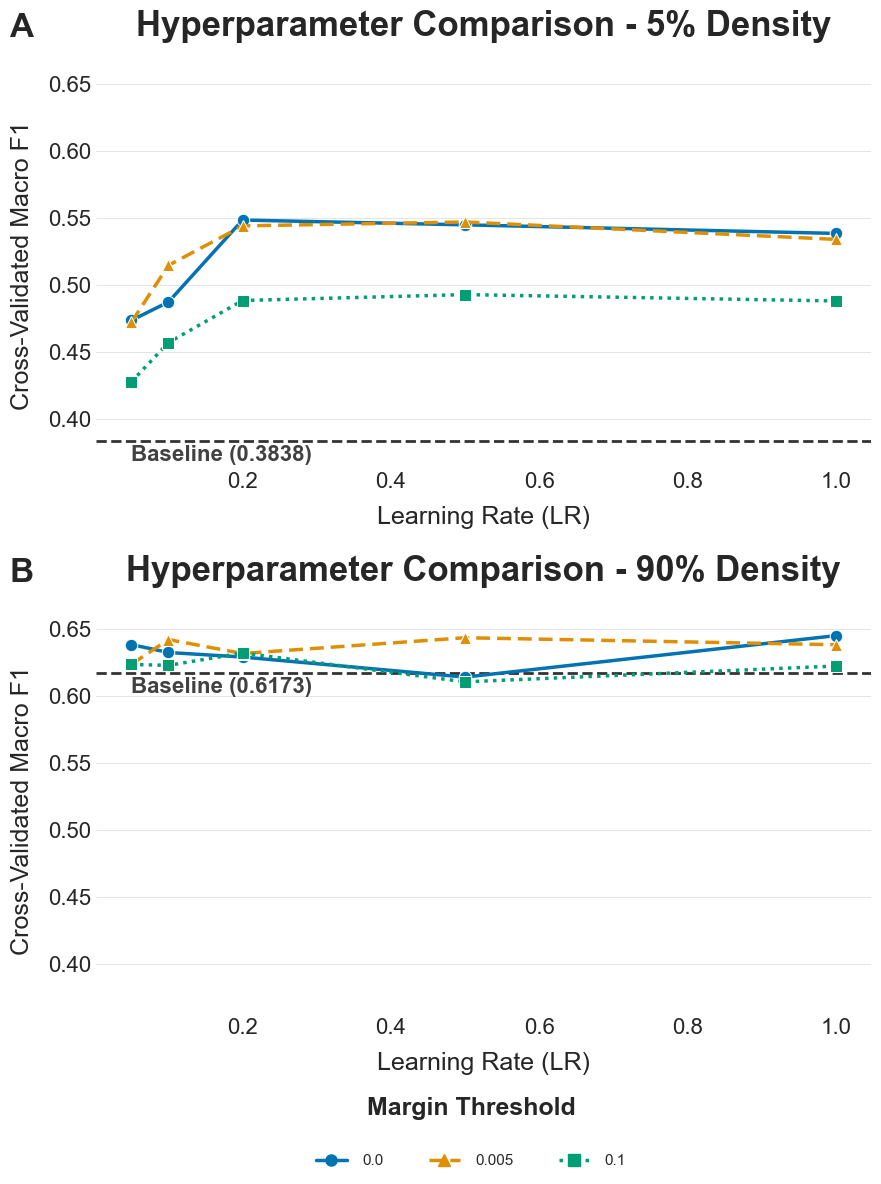

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="white")

margins = sorted(df_cv['Margin'].unique())

# 1. Define Colorblind Colors
margin_palette = sns.color_palette("colorblind", n_colors=len(margins)) 
margin_color_dict = dict(zip(margins, margin_palette))

# 2. Define Unique Markers and Tuple-based Dash Sequences
available_markers = ['o', '^', 's', 'D', 'v', 'p'] 
available_dashes = ["", (4, 2), (1, 1.5), (4, 2, 1, 2), (2, 2), (5, 2, 1, 2, 1, 2)]

# Map them dynamically
margin_marker_dict = {m: available_markers[i % len(available_markers)] for i, m in enumerate(margins)}
margin_dashes_dict = {m: available_dashes[i % len(available_dashes)] for i, m in enumerate(margins)}

# Calculate global Y-axis limits so both plots share the exact same scale perfectly
y_min = df_cv[['Mean_F1', 'CV_Baseline_F1']].min().min() - 0.02
y_max = df_cv[['Mean_F1', 'CV_Baseline_F1']].max().max() + 0.02

# Initialize the 2x1 grid (Top and Bottom)
fig, axes = plt.subplots(2, 1, figsize=(10, 13), sharey=True)
# hspace controls the vertical gap between A and B. 
# bottom makes room for the legend.
plt.subplots_adjust(hspace=0.35, bottom=0.15) 

# Loop through the densities and the axes
for idx, k in enumerate([5, 90]):
    ax = axes[idx]
    k_str = f"{k}%"
    sub_df = df_cv[df_cv['Density'] == k_str]
    baseline_val = sub_df['CV_Baseline_F1'].iloc[0]

    # Draw Main Lines
    sns.lineplot(
        data=sub_df, x="LR", y="Mean_F1", 
        hue="Margin", style="Margin",              
        palette=margin_color_dict, 
        markers=margin_marker_dict,                
        dashes=margin_dashes_dict,                 
        markersize=9, linewidth=2.5, ax=ax, legend=False, zorder=3,
        errorbar=None
    )

    # Draw Baseline
    ax.axhline(baseline_val, ls='--', color='black', alpha=0.8, linewidth=2, zorder=1)
    
    # Add floating text for the baseline
    ax.text(
        x=sub_df['LR'].min(), y=baseline_val - 0.015, 
        s=f'Baseline ({baseline_val:.4f})', 
        color='#2c2c2c', fontweight='bold', fontsize=16, alpha=0.9
    )

    # --- ADD THE A & B LABELS ---
    # Shifted slightly further left (-0.08) to account for the narrower plot width
    letter = "A" if idx == 0 else "B"
    ax.text(
        -0.08, 1.05, letter, transform=ax.transAxes, 
        fontsize=24, fontweight='bold', va='bottom', ha='right'
    )

    # Visual Styling
    ax.set_title(f"Hyperparameter Comparison - {k_str} Density", fontsize=25, fontweight='bold', pad=20)
    ax.set_xlabel("Learning Rate (LR)", fontsize=18, labelpad=10)
    
    # Apply the Y-label to both plots since they are stacked vertically
    ax.set_ylabel("Cross-Validated Macro F1", fontsize=18, labelpad=10)

    # Force the shared Y-axis scale
    ax.set_ylim(y_min, y_max)

    # Apply Tufte Minimalism
    sns.despine(ax=ax, left=True, bottom=True)
    ax.grid(axis='y', color='gray', linestyle='-', linewidth=0.5, alpha=0.3, zorder=0)
    ax.grid(axis='x', visible=False) 
    ax.tick_params(axis='both', which='both', length=0, labelsize=16)

# --- RENDER THE SINGLE SHARED LEGEND ---
handles = []
for m in margins:
    line = plt.Line2D(
        [0], [0], 
        color=margin_color_dict[m], 
        marker=margin_marker_dict[m], 
        lw=2.5, markersize=8
    )
    d = margin_dashes_dict[m]
    if d == "":
        line.set_linestyle('-') 
    else:
        line.set_dashes(d)      
    handles.append(line)

labels = [str(m) for m in margins]

fig.legend(
    handles, labels, title="Margin Threshold\n",
    title_fontproperties={'weight':'bold', 'size': 18},
    ncol=len(margins), loc='lower center',
    bbox_to_anchor=(0.5, 0.02), frameon=False,
    handletextpad=1.0, columnspacing=3.0
)

# Save and show the fully fused figure
combined_file = os.path.join(RESULTS_DIR, "hdc_stylized_line_plots_vertical.png")
plt.savefig(combined_file, dpi=300, bbox_inches='tight')
plt.show()

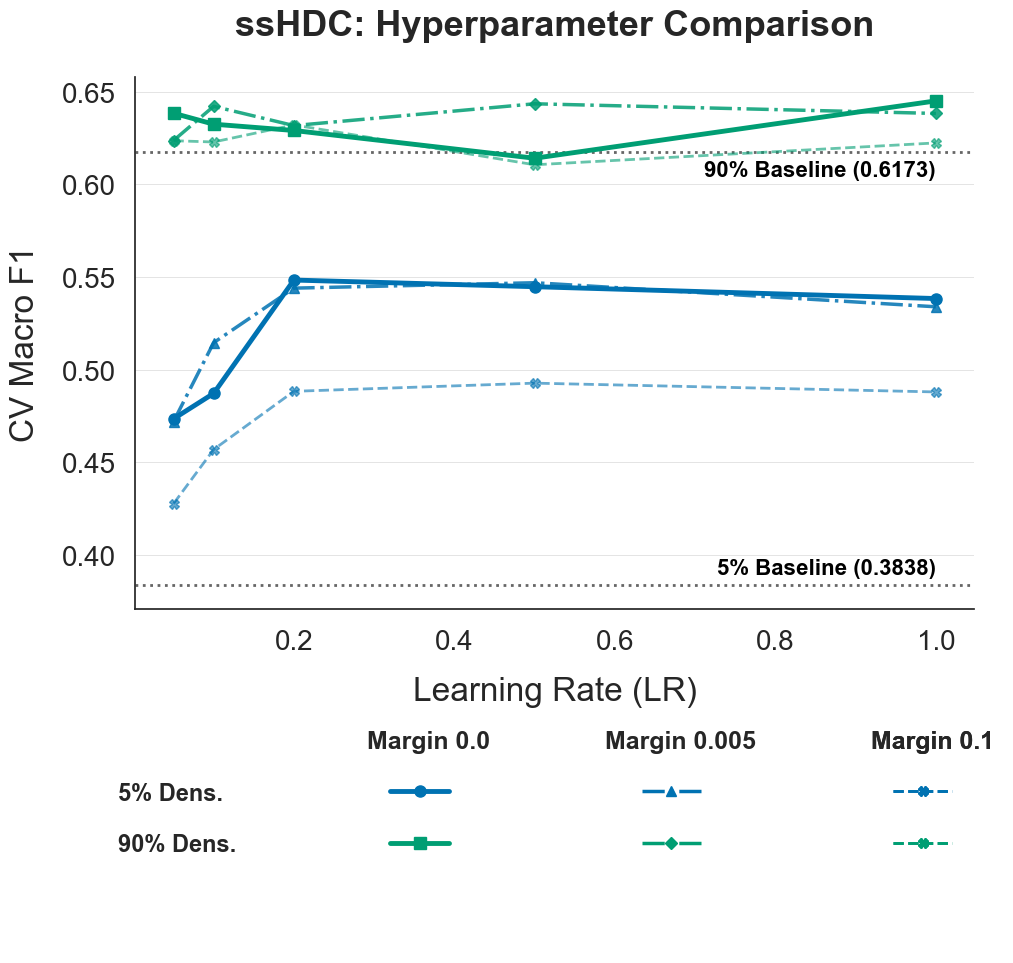

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec

# --- AGGRESSIVE FONT SCALING FOR 2-COLUMN PAPERS ---
TITLE_SIZE = 26
LABEL_SIZE = 24
TICK_SIZE = 20
LEGEND_TITLE_SIZE = 18
LEGEND_TEXT_SIZE = 17
ANNOTATION_SIZE = 16

sns.set_theme(style="white")

# Increased overall figure height to 10x10 to prevent vertical squeezing
fig = plt.figure(figsize=(10, 10))

# IMPORTANT FIX: Changed height_ratios to [3.5, 1.5]. 
# This gives the invisible legend axis 30% of the figure height, ensuring it cannot fall off.
gs = gridspec.GridSpec(2, 1, height_ratios=[3.5, 1.5]) 

ax = fig.add_subplot(gs[0])
ax_leg = fig.add_subplot(gs[1])
ax_leg.axis('off') 

color_5 = '#0072B2'
color_90 = '#009E73'

# --- 2. PLOT 5% DENSITY ---
df_5 = df_cv[df_cv['Density'] == '5%']
base_5 = df_5['CV_Baseline_F1'].iloc[0]

df_5_m0 = df_5[df_5['Margin'] == 0.0].sort_values('LR')
ax.plot(df_5_m0['LR'], df_5_m0['Mean_F1'], color=color_5, ls='-', marker='o', lw=3.5, markersize=8, zorder=5)

if 0.005 in df_5['Margin'].values:
    df_5_m005 = df_5[df_5['Margin'] == 0.005].sort_values('LR')
    ax.plot(df_5_m005['LR'], df_5_m005['Mean_F1'], color=color_5, ls='-.', marker='^', lw=2.5, markersize=7, alpha=0.85, zorder=4)

if 0.1 in df_5['Margin'].values:
    df_5_m1 = df_5[df_5['Margin'] == 0.1].sort_values('LR')
    ax.plot(df_5_m1['LR'], df_5_m1['Mean_F1'], color=color_5, ls='--', marker='X', lw=2, markersize=7, alpha=0.6, zorder=3)

ax.axhline(base_5, ls=':', color="black", alpha=0.6, linewidth=2, zorder=1)
ax.text(df_5['LR'].max(), base_5 + 0.004, f'5% Baseline ({base_5:.4f})', 
        color="black", fontweight='bold', fontsize=ANNOTATION_SIZE, va='bottom', ha='right')

# --- 3. PLOT 90% DENSITY ---
df_90 = df_cv[df_cv['Density'] == '90%']
base_90 = df_90['CV_Baseline_F1'].iloc[0]

df_90_m0 = df_90[df_90['Margin'] == 0.0].sort_values('LR')
ax.plot(df_90_m0['LR'], df_90_m0['Mean_F1'], color=color_90, ls='-', marker='s', lw=3.5, markersize=8, zorder=5)

if 0.005 in df_90['Margin'].values:
    df_90_m005 = df_90[df_90['Margin'] == 0.005].sort_values('LR')
    ax.plot(df_90_m005['LR'], df_90_m005['Mean_F1'], color=color_90, ls='-.', marker='D', lw=2.5, markersize=6, alpha=0.85, zorder=4)

if 0.1 in df_90['Margin'].values:
    df_90_m1 = df_90[df_90['Margin'] == 0.1].sort_values('LR')
    ax.plot(df_90_m1['LR'], df_90_m1['Mean_F1'], color=color_90, ls='--', marker='X', lw=2, markersize=7, alpha=0.6, zorder=3)

ax.axhline(base_90, ls=':', color="black", alpha=0.6, linewidth=2, zorder=1)
ax.text(df_90['LR'].max(), base_90 - 0.004, f'90% Baseline ({base_90:.4f})', 
        color="black", fontweight='bold', fontsize=ANNOTATION_SIZE, va='top', ha='right')

# --- 4. VISUAL STYLING ---
ax.set_title("ssHDC: Hyperparameter Comparison", fontsize=TITLE_SIZE, fontweight='bold', pad=30)
ax.set_xlabel("Learning Rate (LR)", fontsize=LABEL_SIZE, labelpad=15)
ax.set_ylabel("CV Macro F1", fontsize=LABEL_SIZE, labelpad=15)

ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE, pad=8)
sns.despine(ax=ax, left=False, bottom=False)
ax.grid(axis='y', color='gray', linestyle='-', linewidth=0.5, alpha=0.3, zorder=0)

# --- 5. THE MULTI-LEGEND ---
leg_kwargs = {
    'frameon': False, 
    'loc': 'center', 
    'labelspacing': 1.2, 
    'fontsize': LEGEND_TEXT_SIZE,
    'title_fontproperties': {'weight': 'bold', 'size': LEGEND_TITLE_SIZE}
}

# Anchored higher up in the legend area (0.7 instead of 0.5) to clear the bottom boundary
legend_y_pos = 0.7 

# Group 1: Labels
leg_rows = ax_leg.legend(
    handles=[mlines.Line2D([], [], color='none'), mlines.Line2D([], [], color='none')],
    labels=['5% Dens.', '90% Dens.'],
    title=' ', 
    bbox_to_anchor=(0.05, legend_y_pos), 
    handlelength=0, handletextpad=0,
    prop={'weight': 'bold', 'size': LEGEND_TEXT_SIZE}, 
    **leg_kwargs
)
ax_leg.add_artist(leg_rows) 

# Margin = 0.0
leg_m0 = ax_leg.legend(
    handles=[
        mlines.Line2D([0], [0], color=color_5, lw=3.5, ls='-', marker='o', markersize=8),
        mlines.Line2D([0], [0], color=color_90, lw=3.5, ls='-', marker='s', markersize=8)
    ],
    labels=[' ', ' '],
    title='Margin 0.0',
    bbox_to_anchor=(0.35, legend_y_pos), 
    handlelength=2.5, handletextpad=0.5,
    **leg_kwargs
)
ax_leg.add_artist(leg_m0)

# Margin = 0.005
leg_m005 = ax_leg.legend(
    handles=[
        mlines.Line2D([0], [0], color=color_5, lw=2.5, ls='-.', marker='^', markersize=7),
        mlines.Line2D([0], [0], color=color_90, lw=2.5, ls='-.', marker='D', markersize=6)
    ],
    labels=[' ', ' '],
    title='Margin 0.005',
    bbox_to_anchor=(0.65, legend_y_pos), 
    handlelength=2.5, handletextpad=0.5,
    **leg_kwargs
)
ax_leg.add_artist(leg_m005)

# Margin = 0.1
leg_m1 = ax_leg.legend(
    handles=[
        mlines.Line2D([0], [0], color=color_5, lw=2, ls='--', marker='X', markersize=7),
        mlines.Line2D([0], [0], color=color_90, lw=2, ls='--', marker='X', markersize=7)
    ],
    labels=[' ', ' '],
    title='Margin 0.1',
    bbox_to_anchor=(0.95, legend_y_pos), 
    handlelength=2.5, handletextpad=0.5,
    **leg_kwargs
)
ax_leg.add_artist(leg_m1)

# Using tight_layout with a rect ensures the padding respects our boundaries
plt.tight_layout(rect=[0, 0, 1, 0.98])

# NOTE: When saving for the paper, add `bbox_inches='tight'` to guarantee nothing gets clipped!
# plt.savefig("my_plot.pdf", dpi=300, bbox_inches='tight')

plt.show()

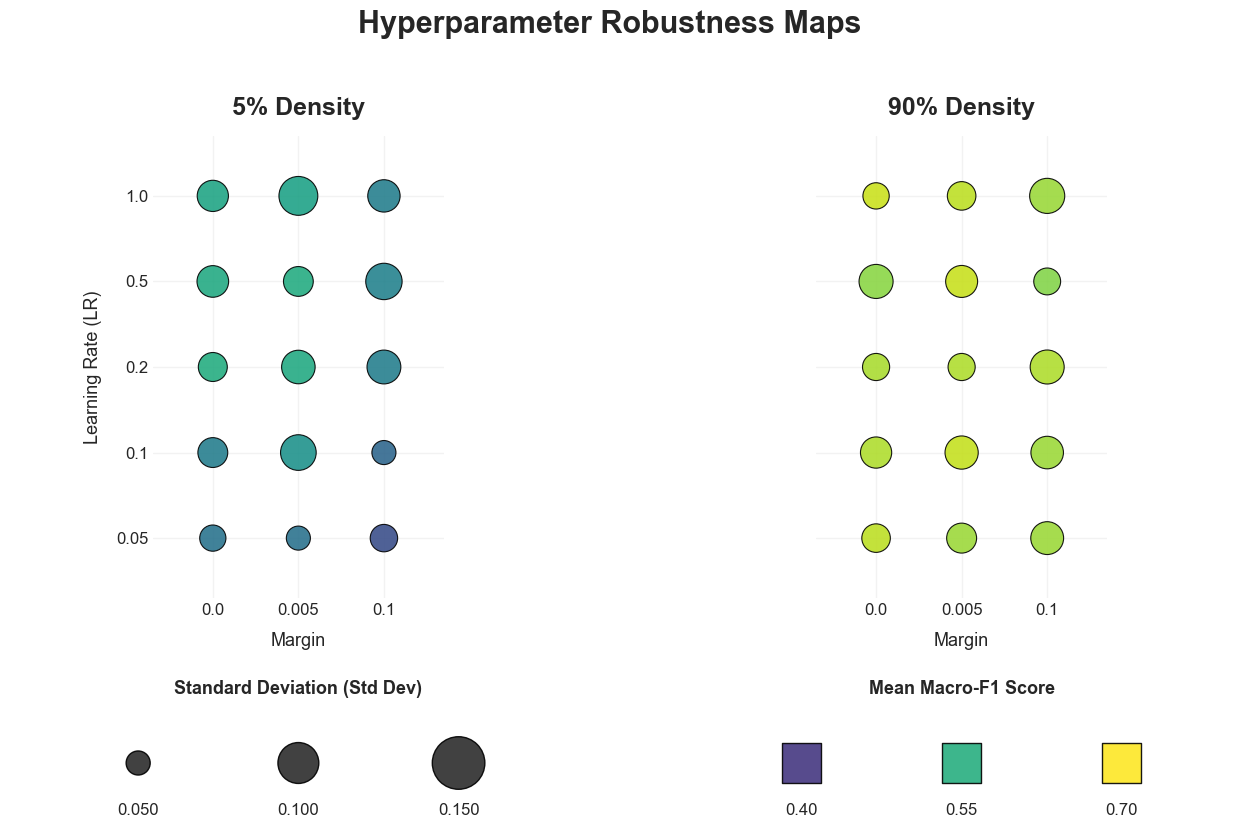

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
import seaborn as sns
import os

# 1. Setup Data and Style
sns.set_theme(style="white")

margins = sorted(df_cv['Margin'].unique())
lrs = sorted(df_cv['LR'].unique())

# Define visual constants from your layout
s_min, s_max = 300, 2000
std_min_val = 0.050
std_max_val = 0.200

# Continuous Color mapping for Mean F1
# (Adjust vmin and vmax if you want to stretch/compress the color scale)
f1_vmin, f1_vmax = 0.35, 0.67
cmap = plt.get_cmap('viridis')
color_norm = Normalize(vmin=f1_vmin, vmax=f1_vmax)

# 2. Setup Layout Grid (2 Columns for the 2 Densities)
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 0.25], wspace=0.15, hspace=0.4)
plot_axes = [fig.add_subplot(gs[0, i]) for i in range(2)]

# 3. Render Main Dotplots
for i, k in enumerate([5, 90]):
    ax = plot_axes[i]
    k_str = f"{k}%"
    subset = df_cv[df_cv['Density'] == k_str].copy()

    # Calculate sizes based on standard deviation
    std = subset['SD_F1']
    std_clipped = np.clip(std, std_min_val, std_max_val)
    sizes = ((std_clipped - std_min_val) / (std_max_val - std_min_val + 1e-9)) * (s_max - s_min) + s_min

    # Map axis coordinates
    x_map = {val: j for j, val in enumerate(margins)}
    y_map = {val: j for j, val in enumerate(lrs)}

    # Render Scatter with F1 color mapping
    ax.scatter(
        subset['Margin'].map(x_map), 
        subset['LR'].map(y_map),
        s=sizes, 
        c=subset['Mean_F1'],       # <-- Color is now F1 Score
        cmap=cmap, 
        norm=color_norm,           # <-- Locks the scale across both plots
        edgecolors='black', linewidths=0.8, alpha=0.9, zorder=3
    )
    
    # CRITICAL: This makes the grid square and the dots "touch"
    ax.set_aspect('equal')
    
    # Visual Styling
    ax.grid(True, linestyle='-', color='gray', alpha=0.1, zorder=1)
    ax.set_xticks(range(len(margins)))
    ax.set_xticklabels(margins, fontsize=12)
    ax.set_yticks(range(len(lrs)))
    ax.set_yticklabels(lrs, fontsize=12)

    # Prevents edge clipping
    ax.set_xlim(-0.7, len(margins) - 0.3)
    ax.set_ylim(-0.7, len(lrs) - 0.3)

    ax.set_title(f"{k_str} Density", fontweight='bold', fontsize=18, pad=15)
    ax.set_xlabel("Margin", fontsize=13, labelpad=10)
    if i == 0: 
        ax.set_ylabel("Learning Rate (LR)", fontsize=13, labelpad=10)
    else: 
        ax.set_yticklabels([])

    sns.despine(ax=ax, left=True, bottom=True)
    ax.tick_params(axis='both', which='both', length=0)

# 4. Render Horizontal Legends

# --- Standard Deviation Legend (Left) ---
ax_size_leg = fig.add_subplot(gs[1, 0])
ax_size_leg.axis('off')
ax_size_leg.set_title("Standard Deviation (Std Dev)", fontsize=13, fontweight='bold', y=1.1)

std_ticks = [0.050, 0.100, 0.150]
leg_sizes = ((np.array(std_ticks) - std_min_val) / (std_max_val - std_min_val)) * (s_max - s_min) + s_min
leg_x = [0, 1, 2]

ax_size_leg.scatter(leg_x, [0]*3, s=leg_sizes, c='#2c2c2c', alpha=0.9, edgecolors='black')
for x, val in zip(leg_x, std_ticks):
    ax_size_leg.text(x, -1.2, f"{val:.3f}", ha='center', va='top', fontsize=12)

ax_size_leg.set_xlim(-0.8, 2.8)
ax_size_leg.set_ylim(-2, 1.5)

# --- Mean F1 Color Legend (Right) ---
ax_color_leg = fig.add_subplot(gs[1, 1])
ax_color_leg.axis('off')
ax_color_leg.set_title("Mean Macro-F1 Score", fontsize=13, fontweight='bold', y=1.1)

# F1 values for the legend squares (matches your provided layout)
f1_ticks = [0.40, 0.55, 0.70] 
leg_colors = cmap(color_norm(f1_ticks))

# Plot the F1 colors as square markers
ax_color_leg.scatter(leg_x, [0]*3, s=800, c=leg_colors, marker='s', alpha=0.9, edgecolors='black')
for x, val in zip(leg_x, f1_ticks):
    ax_color_leg.text(x, -1.2, f"{val:.2f}", ha='center', va='top', fontsize=12)

ax_color_leg.set_xlim(-0.8, 2.8)
ax_color_leg.set_ylim(-2, 1.5)

# Final Polish
plt.suptitle("Hyperparameter Robustness Maps", fontsize=22, fontweight='bold', y=1.02)
dot_file = os.path.join(RESULTS_DIR, "hdc_stylized_dot_plots_f1.png")
plt.savefig(dot_file, dpi=300, bbox_inches='tight')
plt.show()

Processing 5% Density...
Processing 90% Density...
t-SNE Visualization saved to: Final_Final_SurpriseResults_10.000\hdc_tsne_prototypes.png


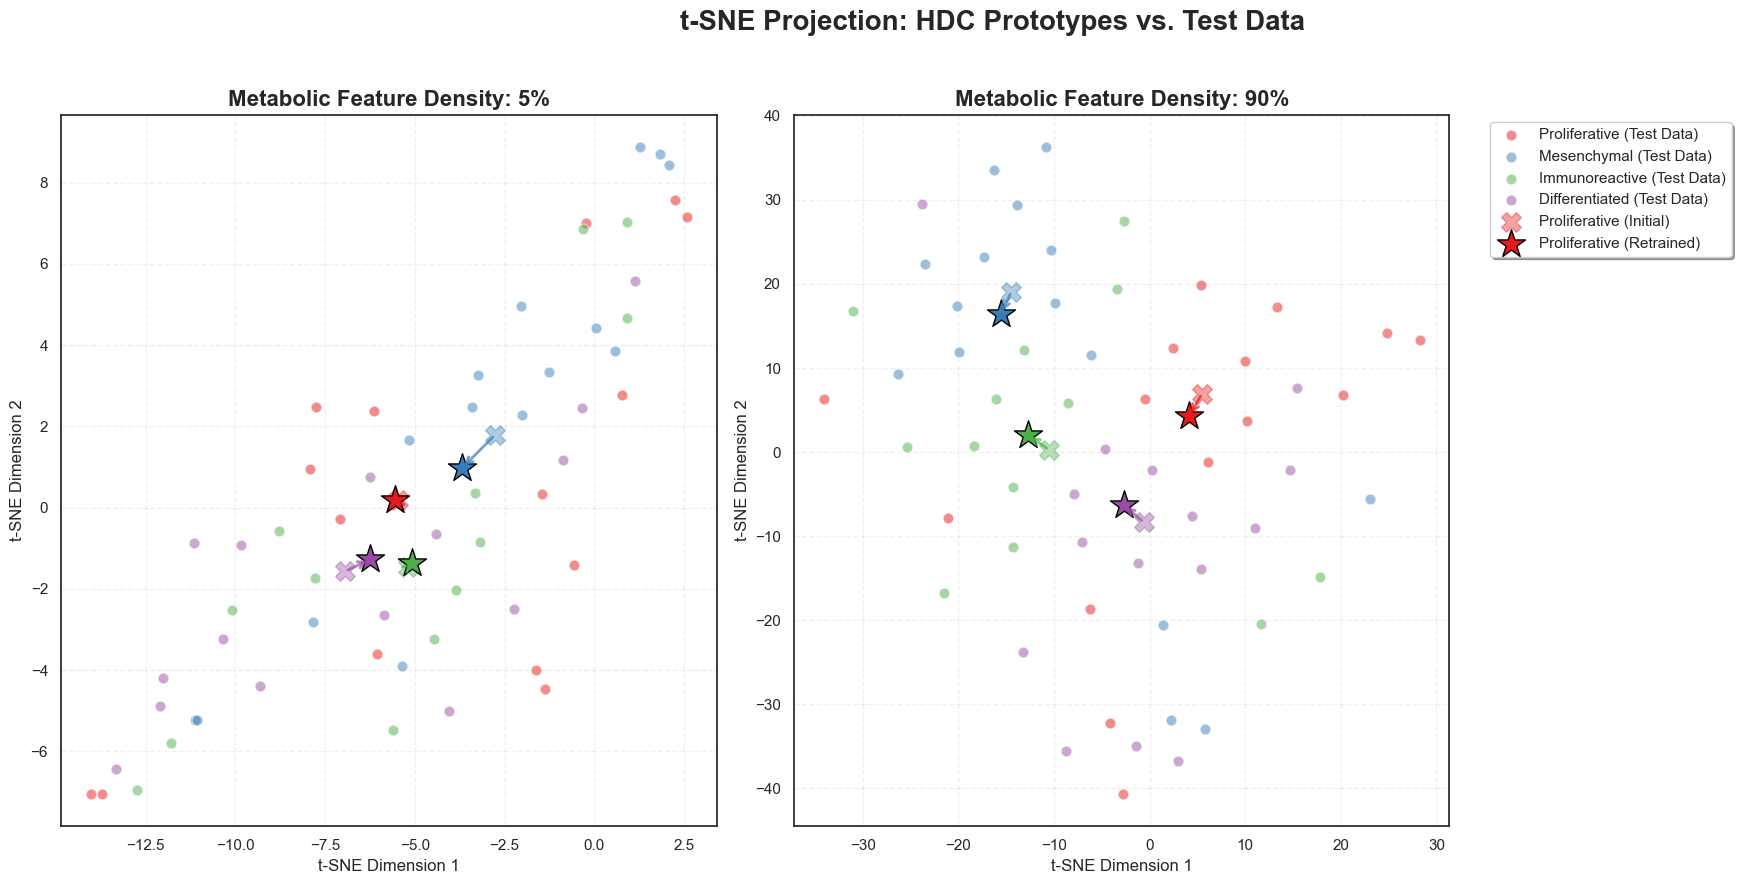

In [71]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
import os

# Configuration
RESULTS_DIR = "Final_Final_SurpriseResults_10.000"
DENSITIES = [5, 90]
RANDOM_SEED = 42

# Subtype mapping for the legend
SUBTYPE_NAMES = {
    0: "Proliferative",
    1: "Mesenchymal", 
    2: "Immunoreactive", 
    3: "Differentiated"
}
COLORS = sns.color_palette("Set1", n_colors=4)

# Setup Figure
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
plt.suptitle("t-SNE Projection: HDC Prototypes vs. Test Data", fontsize=20, fontweight='bold', y=0.98)

for idx, k in enumerate(DENSITIES):
    file_path = os.path.join(RESULTS_DIR, f"tsne_data_density_{k}.pt")
    
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}. Skipping.")
        continue
        
    print(f"Processing {k}% Density...")
    
    # 1. Load the Data
    data = torch.load(file_path, weights_only=False)
    X_test_hvs = data['X_test_hvs'].numpy()
    y_test_labels = data['y_test_labels'].numpy()
    init_p = data['initial_prototypes']
    final_p = data['retrained_prototypes']
    
    classes = sorted(list(init_p.keys()))
    num_classes = len(classes)
    num_test_samples = len(X_test_hvs)
    
    # Extract prototype tensors into arrays in sorted class order
    init_p_arrays = np.array([init_p[c].numpy() for c in classes])
    final_p_arrays = np.array([final_p[c].numpy() for c in classes])
    
    # 2. Concatenate Everything for a Unified t-SNE Space
    # Order: [Test Data (N), Initial Protos (4), Final Protos (4)]
    X_all = np.vstack([X_test_hvs, init_p_arrays, final_p_arrays])
    
    # 3. Run t-SNE
    # Note: Perplexity must be lower than the number of samples (~66 total). 15 is a safe value.
    tsne = TSNE(n_components=2, perplexity=15, random_state=RANDOM_SEED, init='pca', learning_rate='auto')
    X_tsne = tsne.fit_transform(X_all)
    
    # 4. Split the 2D coordinates back out
    tsne_test = X_tsne[:num_test_samples]
    tsne_init = X_tsne[num_test_samples : num_test_samples + num_classes]
    tsne_final = X_tsne[num_test_samples + num_classes :]
    
    # 5. Plotting
    ax = axes[idx]
    
    # Plot Test Data
    for c_idx, c in enumerate(classes):
        mask = (y_test_labels == c)
        ax.scatter(
            tsne_test[mask, 0], tsne_test[mask, 1], 
            color=COLORS[c_idx], alpha=0.5, s=60, 
            label=f"{SUBTYPE_NAMES[c]} (Test Data)", edgecolors='white'
        )
        
    # Plot Initial Prototypes (Faded 'X')
    for c_idx, c in enumerate(classes):
        ax.scatter(
            tsne_init[c_idx, 0], tsne_init[c_idx, 1], 
            color=COLORS[c_idx], marker='X', s=200, alpha=0.4,
            label=f"{SUBTYPE_NAMES[c]} (Initial)" if c_idx == 0 else "" # Only label once to avoid legend clutter
        )
        
    # Plot Retrained Prototypes (Bold Stars)
    for c_idx, c in enumerate(classes):
        ax.scatter(
            tsne_final[c_idx, 0], tsne_final[c_idx, 1], 
            color=COLORS[c_idx], marker='*', s=450, alpha=1.0, edgecolors='black',
            label=f"{SUBTYPE_NAMES[c]} (Retrained)" if c_idx == 0 else ""
        )
        
        # Draw Arrows from Initial to Retrained Prototype
        ax.annotate(
            '', xy=(tsne_final[c_idx, 0], tsne_final[c_idx, 1]), 
            xytext=(tsne_init[c_idx, 0], tsne_init[c_idx, 1]),
            arrowprops=dict(arrowstyle="->", color=COLORS[c_idx], lw=2, alpha=0.7)
        )

    # Aesthetics
    ax.set_title(f"Metabolic Feature Density: {k}%", fontsize=16, fontweight='bold')
    ax.set_xlabel("t-SNE Dimension 1", fontsize=12)
    ax.set_ylabel("t-SNE Dimension 2", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Clean up the legend (put it outside the plot)
    if idx == 1:
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11, frameon=True, shadow=True)

plt.tight_layout(rect=[0, 0, 0.88, 0.96]) # Leave room for the external legend
tsne_out_path = os.path.join(RESULTS_DIR, "hdc_tsne_prototypes.png")
plt.savefig(tsne_out_path, dpi=300, bbox_inches='tight')
print(f"t-SNE Visualization saved to: {tsne_out_path}")
plt.show()